# 00 — A 5-layer RNN and a 5-layer LSTM as compositions of elementary functions

A deep recurrent network looks like a black box with a million numbers inside, but it is built from very few ingredients. The idea of this notebook, taken from the lecturer's tutorial on deep learning as function composition, is that **a network is a structured composition of simple functions**, $f_L\circ\dots\circ f_1$. If we understand each simple function and the way they are chained, we understand the network, and nothing in it is magic.

Five elementary operations are enough for everything in this assignment: the **matrix product**, **addition**, **tanh**, **sigmoid** and the **element-wise product** $\odot$. We first meet them one by one (§1), then build a single RNN cell from three of them (§2), stack five of these cells into a 5-layer RNN (§3) and discover, by following the gradient, why such a network struggles with long sequences (§4). The LSTM cell (§5) is then introduced as an *improvement of the RNN that fixes exactly this limitation*, again built from the same five operations, and §6 repeats the gradient experiment for it. Every network is written out by hand in NumPy on numbers small enough to read, and then compared with PyTorch (`nn.RNN`, `nn.LSTM`) and Keras (`SimpleRNN`, `LSTM`) to prove that the libraries compute exactly the function we wrote down.

**Notation.** A sequence has $T$ steps and each step is a vector $x_t\in\mathbb{R}^F$ of $F$ numbers. A layer has $H$ hidden units. Layers are numbered $l=1..L$ with $L=5$, and $h^{(l)}_t$ is the hidden state of layer $l$ at step $t$. Vectors are row vectors, so a layer is written $xW$.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from pathlib import Path
np.set_printoptions(precision=4, suppress=True)
IMG = Path("report/images"); IMG.mkdir(parents=True, exist_ok=True)      # figures used by the report

# ---- shared look of every chart: warm paper, no boxes or grid lines, direct labels instead of legends ----
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle, Rectangle, Polygon
C = dict(rnn="#12a39a", lstm="#d6336c", pos="#dd9a00", neg="#5a4bd1", ink="#1f2430", mute="#8c8a85", rule="#e4dfd5", paper="#fbf8f2",
         base="#8c8a85", faint="#ddd7ca", teal_l="#cfe9e6", mag_l="#f6cddb", amb_l="#f7e2b0", ind_l="#d5d0f3")
SEQ = LinearSegmentedColormap.from_list("seq", ["#f3efe6", "#a8dcd5", "#12a39a", "#0a5c63"])      # one hue, light -> dark
DIV = LinearSegmentedColormap.from_list("div", ["#5a4bd1", "#f3efe6", "#d6336c"])                  # two hues around a neutral middle
DUO = LinearSegmentedColormap.from_list("duo", [C["rnn"], "#f3efe6", C["lstm"]])                 # teal = RNN side, magenta = LSTM side
CLS = LinearSegmentedColormap.from_list("cls", [C["pos"], "#f3efe6", C["neg"]])                  # amber = positive side, indigo = negative side
plt.rcParams.update({
    "figure.facecolor": C["paper"], "axes.facecolor": C["paper"], "savefig.facecolor": C["paper"], "figure.dpi": 100, "savefig.dpi": 170,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10, "text.color": C["ink"], "axes.labelcolor": C["mute"],
    "xtick.color": C["mute"], "ytick.color": C["mute"], "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.grid": False, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False})

def headline(fig, title, sub=""):
    """big serif title and a grey sub-title in the top-left corner of the figure"""
    h = fig.get_figheight()
    fig.text(0.004, 1 - 0.05 / h, title, fontsize=15, fontweight="bold", family=["Georgia", "DejaVu Serif"], va="top")
    if sub: fig.text(0.004, 1 - 0.40 / h, sub, fontsize=9.5, color=C["mute"], va="top")

def finish(fig, name, top_in=1.1):
    h = fig.get_figheight(); fig.subplots_adjust(left=0.06, right=0.985, bottom=0.11, top=1 - top_in / h)
    plt.savefig(IMG / f"{name}.png", bbox_inches="tight"); plt.show()

def style(run_id):
    """colour = architecture, line style = framework (the same in every chart)"""
    return dict(color=C["rnn"] if run_id.endswith("RNN") else C["lstm"], ls="-" if "-TF-" in run_id else "--")

def mk(run_id): return "o" if "-TF-" in run_id else "s"        # circle = TensorFlow, square = PyTorch
torch.manual_seed(0)
print(f"Using PyTorch {torch.__version__} and TensorFlow {tf.__version__}.")

Using PyTorch 2.14.1+cpu and TensorFlow 2.22.0-rc0.


## 1. The elementary functions

Suppose we want a function that reads a sequence of numbers and produces a decision. What is the smallest set of operations we need? The table lists the five we will use, each with a tiny example you can check by hand.

| Function | Formula | Tiny example |
|---|---|---|
| matrix product | $(xW)_j=\sum_i x_iW_{ij}$ | $(1,2)\begin{pmatrix}1&0\\3&1\end{pmatrix}=(7,2)$ |
| addition | $a+b$ | $(7,2)+(0.5,-1)=(7.5,1)$ |
| tanh | $\tanh z=\frac{e^z-e^{-z}}{e^z+e^{-z}}\in(-1,1)$ | $\tanh(0.5)=0.4621$, $\tanh(3)=0.9951$ |
| sigmoid | $\sigma(z)=\frac1{1+e^{-z}}\in(0,1)$ | $\sigma(0)=0.5$, $\sigma(2)=0.8808$ |
| element-wise product | $(a\odot b)_i=a_ib_i$ | $(0.9,0.1)\odot(4,4)=(3.6,0.4)$ |

Why these five and not others? The argument is a short chain of "what goes wrong without it".

- **Matrix product.** Each hidden unit has to look at *every* input value, giving each its own importance (its weight): unit $j$ computes $\sum_ix_iW_{ij}$. A matrix product does this for all units at once, and the numbers in $W$ are what training adjusts.
- **Addition.** The cell has to merge two sources of information, the new input and its own memory. Adding them keeps both, and the derivative of a sum is 1, so gradients pass through an addition unchanged (this will become important for the LSTM).
- **A nonlinearity (tanh, sigmoid).** Without one, depth is useless: two linear layers collapse into one, $(xW_1)W_2=x(W_1W_2)$, so five layers without a nonlinearity would equal a single matrix and could only draw straight decision boundaries. The nonlinearity is what lets layers build on each other.
- **tanh rather than ReLU in a recurrent network.** The same weights are applied at every step. ReLU has no upper limit, so if the recurrent weights scale the state by 1.1 per step, after 50 steps it has grown by $1.1^{50}\approx117$. tanh clips every step back into $(-1,1)$, and because it is centred on zero, states can be positive or negative.
- **Sigmoid for gates.** A gate must be a *fraction* between "block everything" (0) and "let everything through" (1), which is exactly the range of $\sigma$. tanh cannot serve as a gate because its range includes negative values, and "let through −30 %" means nothing.
- **The element-wise product $\odot$.** A gate has to control each unit separately (keep unit 1, forget unit 2), so gate and content are multiplied position by position, not with a full matrix.

The two squashing functions also decide how well gradients flow, because the derivative is the factor by which a gradient shrinks when it passes through: $\tanh'(z)=1-\tanh^2 z\le 1$ and $\sigma'(z)=\sigma(z)(1-\sigma(z))\le 0.25$. Both are largest at $z=0$ and nearly zero when $z$ is large in either direction, where the function is *saturated*.

In [2]:
x = np.array([1., 2.]); W = np.array([[1., 0.], [3., 1.]]); b = np.array([0.5, -1.])
sigmoid = lambda z: 1 / (1 + np.exp(-z))
print("matrix product       x W        =", x @ W)
print("plus a bias           x W + b    =", x @ W + b)
print("squashed with tanh    tanh(xW+b) =", np.tanh(x @ W + b))
print("sigmoid of 0 and 2    sigma(z)   =", sigmoid(np.array([0., 2.])))
print("a gate (0.9, 0.1) applied to (4, 4) =", np.array([0.9, 0.1]) * np.array([4., 4.]))
print("derivative of tanh at z = 3:", round(1 - np.tanh(3) ** 2, 4), "(a saturated unit passes on almost no gradient)")

matrix product       x W        = [7. 2.]
plus a bias           x W + b    = [7.5 1. ]
squashed with tanh    tanh(xW+b) = [1.     0.7616]
sigmoid of 0 and 2    sigma(z)   = [0.5    0.8808]
a gate (0.9, 0.1) applied to (4, 4) = [3.6 0.4]
derivative of tanh at z = 3: 0.0099 (a saturated unit passes on almost no gradient)


**Checking the examples.** The printed lines reproduce the table: the matrix product gives $(7,2)$, adding the bias gives $(7.5,1)$, tanh squashes this to $(1.00,0.76)$ (the first number is so large that tanh has saturated at almost exactly 1), the sigmoid maps $0$ and $2$ to $0.5$ and $0.88$, and the gate $(0.9,0.1)$ keeps 90 % of the first value and 10 % of the second, turning $(4,4)$ into $(3.6,0.4)$. The last line is a warning for later: at $z=3$ the derivative of tanh is only $0.0099$, so a saturated unit passes on only one percent of the gradient it receives.

### The activation functions as pictures

The table says what the functions do, the pictures show **why they behave as they do**. The left panel plots the candidates, the middle panel their derivatives (the factor a gradient is multiplied by when it passes through the function) and the right panel what happens when the *same* weight is applied again and again, which is exactly what a recurrent network does.

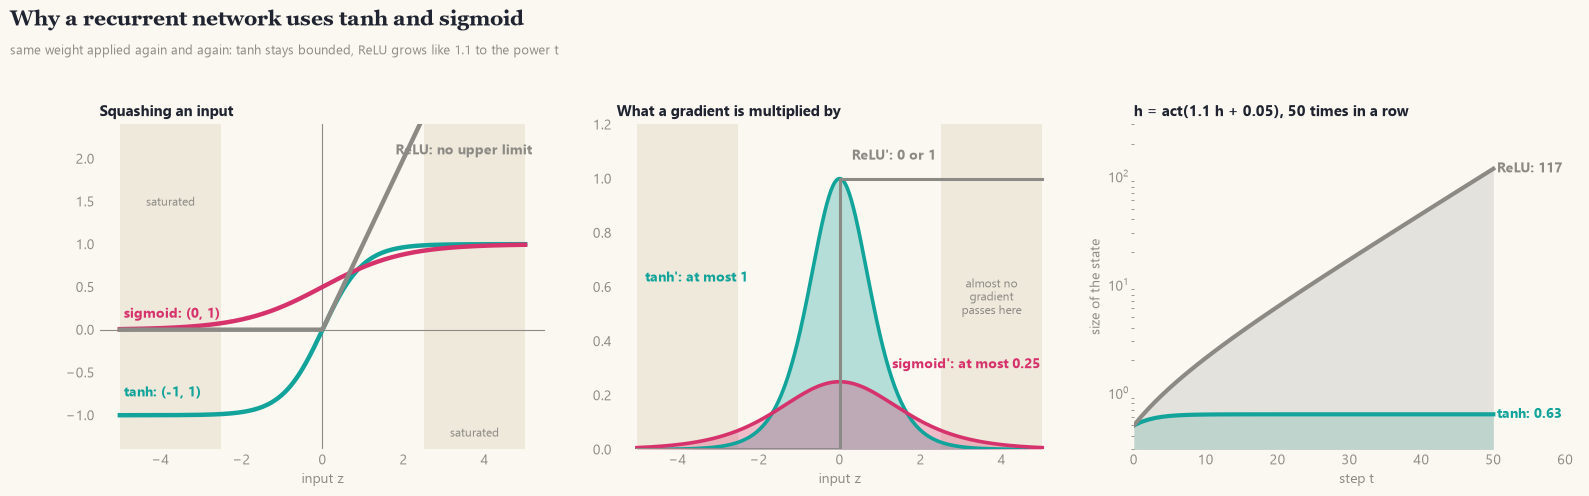

after 50 steps:  tanh -> 0.633   ReLU -> 116.9   (pure growth 1.1^50 = 117)


In [3]:
z = np.linspace(-5, 5, 400)
relu = lambda v: np.maximum(0, v)
fig = plt.figure(figsize=(16, 5)); gs = fig.add_gridspec(1, 3, wspace=0.16)

a = fig.add_subplot(gs[0]); a.axvspan(2.5, 5, color="#efe9dc", lw=0); a.axvspan(-5, -2.5, color="#efe9dc", lw=0)
a.axhline(0, color=C["mute"], lw=0.8); a.axvline(0, color=C["mute"], lw=0.8)
for f, col in [(np.tanh, C["rnn"]), (sigmoid, C["lstm"]), (relu, C["mute"])]: a.plot(z, f(z), color=col, lw=3.2)
a.text(-4.9, -0.78, "tanh: (-1, 1)", color=C["rnn"], fontweight="bold"); a.text(-4.9, 0.14, "sigmoid: (0, 1)", color=C["lstm"], fontweight="bold"); a.text(1.8, 2.05, "ReLU: no upper limit", color=C["mute"], fontweight="bold")
a.text(3.75, -1.25, "saturated", ha="center", fontsize=8.5, color=C["mute"]); a.text(-3.75, 1.45, "saturated", ha="center", fontsize=8.5, color=C["mute"])
a.set_ylim(-1.4, 2.4); a.set_xlabel("input z"); a.set_title("Squashing an input")

b = fig.add_subplot(gs[1]); b.axvspan(2.5, 5, color="#efe9dc", lw=0); b.axvspan(-5, -2.5, color="#efe9dc", lw=0)
b.fill_between(z, 1 - np.tanh(z) ** 2, color=C["rnn"], alpha=0.30, lw=0); b.plot(z, 1 - np.tanh(z) ** 2, color=C["rnn"], lw=2.6)
b.fill_between(z, sigmoid(z) * (1 - sigmoid(z)), color=C["lstm"], alpha=0.30, lw=0); b.plot(z, sigmoid(z) * (1 - sigmoid(z)), color=C["lstm"], lw=2.6)
b.step(z, (z > 0).astype(float), color=C["mute"], lw=2.2, where="post")
b.text(-4.8, 0.62, "tanh': at most 1", color=C["rnn"], fontweight="bold"); b.text(1.3, 0.3, "sigmoid': at most 0.25", color=C["lstm"], fontweight="bold"); b.text(0.3, 1.07, "ReLU': 0 or 1", color=C["mute"], fontweight="bold")
b.text(3.75, 0.5, "almost no\ngradient\npasses here", ha="center", fontsize=8.5, color=C["mute"]); b.set_ylim(0, 1.2); b.set_xlabel("input z"); b.set_title("What a gradient is multiplied by")

c_ = fig.add_subplot(gs[2]); steps = np.arange(0, 51)
for act, col, name in [(np.tanh, C["rnn"], "tanh"), (relu, C["mute"], "ReLU")]:
    h_ = [0.5]
    for _ in steps[1:]: h_.append(act(1.1 * h_[-1] + 0.05))
    c_.fill_between(steps, h_, 0.3, color=col, alpha=0.2, lw=0); c_.plot(steps, h_, color=col, lw=3)
    c_.text(50.5, h_[-1], f"{name}: {h_[-1]:.2f}" if h_[-1] < 10 else f"{name}: {h_[-1]:.0f}", color=col, va="center", fontweight="bold")
c_.set_yscale("log"); c_.set_ylim(0.3, 300); c_.set_xlim(0, 62); c_.set_xlabel("step t"); c_.set_ylabel("size of the state"); c_.set_title("h = act(1.1 h + 0.05), 50 times in a row")
headline(fig, "Why a recurrent network uses tanh and sigmoid", "same weight applied again and again: tanh stays bounded, ReLU grows like 1.1 to the power t")
finish(fig, "C_activations", top_in=1.2)
hs = {}
for name, act in [("tanh", np.tanh), ("ReLU", relu)]:
    v = 0.5
    for _ in range(50): v = act(1.1 * v + 0.05)
    hs[name] = v
print("after 50 steps:  tanh -> %.3f   ReLU -> %.1f   (pure growth 1.1^50 = %.0f)" % (hs["tanh"], hs["ReLU"], 1.1 ** 50))

**Reading the pictures.** On the left, sigmoid and tanh have the same S shape but live in different ranges, $(0,1)$ and $(-1,1)$, while ReLU is a straight line that never stops growing. In the middle we see why saturation hurts: both derivatives are bell-shaped and fall to nearly zero for inputs beyond about $\pm2.5$ (the shaded zones), and the sigmoid's derivative is never larger than 0.25, a quarter of tanh's. A sigmoid unit therefore passes at most a quarter of the gradient, a tanh unit at most all of it. On the right we repeat $h\leftarrow\text{act}(1.1\,h+0.05)$ fifty times, a stand-in for a recurrent layer whose weight is slightly above 1. The tanh state settles at 0.63 and stays there, while the ReLU state grows to 117, which is $1.1^{50}$: a state that explodes in this way would make training impossible, which is why recurrent networks use bounded activations.

## 2. One RNN cell = a composition of three elementary functions

When we read "the phone is not good", the meaning of the last word depends on the words before it. A network that processes each word separately cannot know that "good" was negated. A recurrent network solves this by carrying a **hidden state** $h_t$, a vector that summarises everything read so far. At every step the cell mixes the new input with its own previous state:

$$h_t=\tanh\big(\underbrace{x_tW_x}_{\text{matmul}}+\underbrace{h_{t-1}W_h}_{\text{matmul}}+b\big),\qquad h_0=0 .$$

Written as a composition, $h_t = \tanh\circ\,\mathrm{add}\,(x_tW_x,\;h_{t-1}W_h,\;b)$: two matrix products, one addition, one tanh.

Why does the formula look like this? $x_tW_x$ is *what is new* at step $t$ and $h_{t-1}W_h$ is *what was known before*. Adding them makes the new state depend on both, and tanh keeps it bounded. That is the whole idea of a recurrent network: $h_t$ is a running summary of $x_1,\dots,x_t$. The starting state is $h_0=0$ because before the first step nothing has been read.

**Why the same weights at every step?** The rule for reading a word should not depend on where the word is: "not good" means the same at word 3 and at word 80, and a 2 % price drop means the same on any day. Sharing the weights also keeps the size of the network fixed: one $W_h$ serves sequences of any length. Separate weights for every step would multiply the number of parameters by $T$ and could not process a sequence longer than the ones seen in training. The price of sharing is the nesting that appears when we unroll the recurrence:

$$h_3=\tanh\big(x_3W_x+\tanh\big(x_2W_x+\tanh(x_1W_x+b)\,W_h+b\big)W_h+b\big).$$

The first input $x_1$ reaches $h_3$ only through two layers of $W_h$ and tanh. That nesting is the source of the gradient problem of §4. First, a tiny example with $F=2$ inputs and $H=2$ units, so that every number can be followed.

In [4]:
Wx = np.array([[0.5, -0.3], [0.8, 0.2]]); Wh = np.array([[0.1, 0.4], [-0.2, 0.3]]); bh = np.array([0.0, 0.1])
xs = np.array([[1.0, 0.0], [0.5, 1.0], [0.0, -1.0]])      # T = 3 steps
h = np.zeros(2)
for t, xt in enumerate(xs, 1):
    a = xt @ Wx + h @ Wh + bh                              # matmul, matmul, add
    h = np.tanh(a)                                         # tanh
    print(f"step {t}: pre-activation a = {a}, so the new state is h_{t} = tanh(a) = {h}")

step 1: pre-activation a = [ 0.5 -0.2], so the new state is h_1 = tanh(a) = [ 0.4621 -0.1974]
step 2: pre-activation a = [1.1357 0.2756], so the new state is h_2 = tanh(a) = [0.813  0.2689]
step 3: pre-activation a = [-0.7725  0.3058], so the new state is h_3 = tanh(a) = [-0.6484  0.2966]


**Following the numbers.** Step 1 starts from $h_0=0$, so only the input contributes: $a=x_1W_x+b=(0.5,-0.2)$, and tanh turns it into $h_1=(0.462,-0.197)$. At step 2 the cell mixes the new input with the memory of step 1: the recurrent part $h_1W_h$ shifts the pre-activation to $(1.136,0.276)$ and the state becomes $(0.813,0.269)$. At step 3 the input $(0,-1)$ pushes the state to $(-0.648,0.297)$. Every value stays strictly between $-1$ and $1$, as tanh guarantees, and each state depends on all earlier inputs through the previous state.

### Folded and unrolled

A recurrent cell is drawn in two equivalent ways. **Folded**, it is one box whose output is fed back into itself. **Unrolled**, the same box is copied once per time step; the copies are not separate layers, they are the *same* weights used again. The unrolled picture is the one the gradient follows when we train, because the error at the last step has to travel back through every copy.

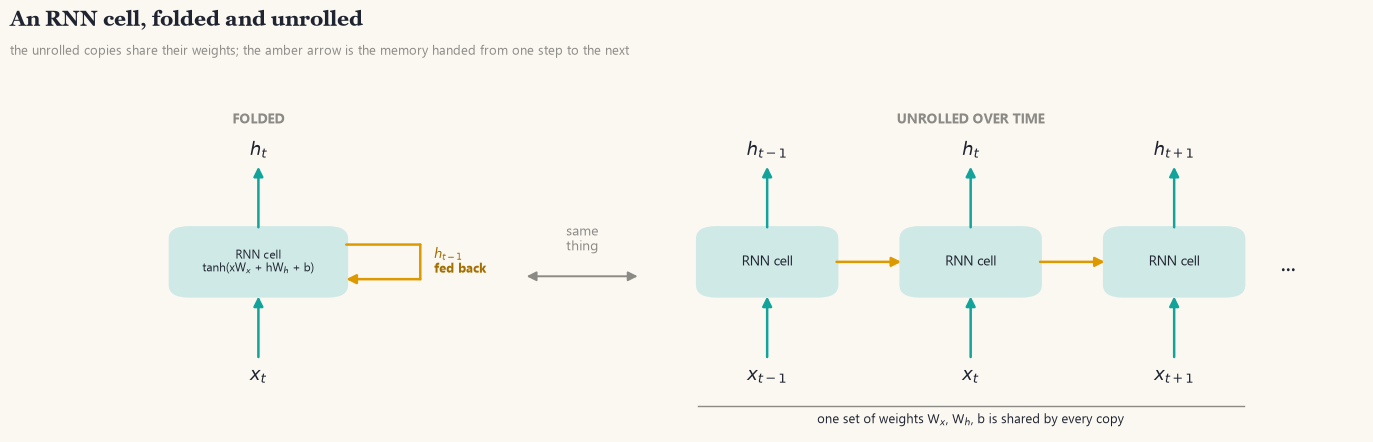

In [5]:
def box(ax, x, y, w, h, text, fc, ec=None, fs=10, **kw):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.22", fc=fc, ec=ec or "none", lw=1.2, **kw))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)
def arrow(ax, p, q, color=C["ink"], rad=0.0, lw=1.8, style="-|>"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle=style, mutation_scale=14, color=color, lw=lw, connectionstyle=f"arc3,rad={rad}", shrinkA=0, shrinkB=0))
UP, TIME = C["rnn"], C["pos"]                      # teal arrows go up through layers, amber arrows go right through time

fig, ax = plt.subplots(figsize=(13.8, 4.8)); ax.set_xlim(0, 13.8); ax.set_ylim(-1.2, 4.3); ax.axis("off")
box(ax, 0.9, 1.15, 1.9, 1.2, "RNN cell\ntanh(xW$_x$ + hW$_h$ + b)", C["teal_l"], fs=8.5)
arrow(ax, (1.85, 0.1), (1.85, 1.15), UP); ax.text(1.85, -0.3, "$x_t$", ha="center", fontsize=13)
arrow(ax, (1.85, 2.35), (1.85, 3.4), UP); ax.text(1.85, 3.6, "$h_t$", ha="center", fontsize=13)
for p, q, s in [((2.8, 2.05), (3.6, 2.05), "-"), ((3.6, 2.05), (3.6, 1.45), "-"), ((3.6, 1.45), (2.8, 1.45), "-|>")]:
    arrow(ax, p, q, TIME, style=s)
ax.text(3.75, 1.75, "$h_{t-1}$\nfed back", ha="left", va="center", fontsize=9, color="#a36f00", fontweight="bold"); ax.text(1.85, 4.15, "FOLDED", ha="center", fontweight="bold", color=C["mute"])
ax.text(5.35, 1.95, "same\nthing", ha="center", fontsize=10, color=C["mute"]); arrow(ax, (4.75, 1.5), (5.95, 1.5), C["mute"], lw=1.4, style="<|-|>")
xs_ = [6.6, 8.8, 11.0]; lab = ["t-1", "t", "t+1"]
for k, x0 in enumerate(xs_):
    box(ax, x0, 1.15, 1.5, 1.2, "RNN cell", C["teal_l"], fs=10)
    arrow(ax, (x0 + 0.75, 0.1), (x0 + 0.75, 1.15), UP); ax.text(x0 + 0.75, -0.3, f"$x_{{{lab[k]}}}$", ha="center", fontsize=13)
    arrow(ax, (x0 + 0.75, 2.35), (x0 + 0.75, 3.4), UP); ax.text(x0 + 0.75, 3.6, f"$h_{{{lab[k]}}}$", ha="center", fontsize=13)
    if k < 2: arrow(ax, (x0 + 1.5, 1.75), (xs_[k + 1], 1.75), TIME)
ax.text(12.9, 1.7, "...", fontsize=18, va="center"); ax.text(8.8 + 0.75, 4.15, "UNROLLED OVER TIME", ha="center", fontweight="bold", color=C["mute"])
ax.plot([6.6, 12.5], [-0.75, -0.75], color=C["mute"], lw=1); ax.text(9.55, -1.05, "one set of weights W$_x$, W$_h$, b is shared by every copy", ha="center", fontsize=9.5)
headline(fig, "An RNN cell, folded and unrolled", "the unrolled copies share their weights; the amber arrow is the memory handed from one step to the next")
finish(fig, "C_unroll")

## 3. Stacking five layers

One layer reads the sequence of inputs and produces a sequence of states. Nothing prevents us from feeding that sequence into a second layer, and a third, and so on. A 5-layer RNN stacks five cells: layer 1 reads the input sequence, and layer $l$ reads the **hidden states of layer $l-1$** as its input sequence:

$$h^{(1)}_t=\tanh\big(x_tW^{(1)}_x+h^{(1)}_{t-1}W^{(1)}_h+b^{(1)}\big),\qquad
h^{(l)}_t=\tanh\big(h^{(l-1)}_tW^{(l)}_x+h^{(l)}_{t-1}W^{(l)}_h+b^{(l)}\big),\ l=2..5 .$$

The prediction uses the top layer at the last step: $\hat y=g\big(h^{(5)}_TW_y+b_y\big)$, with $g=\sigma$ for a yes/no label (review sentiment) or $g=$ identity for a number (stock volatility).

**As one composition.** Call $f^{(l)}$ the map that turns a whole sequence into the sequence of layer-$l$ states. Then

$$\hat y = g\circ\mathrm{last}\circ f^{(5)}\circ f^{(4)}\circ f^{(3)}\circ f^{(2)}\circ f^{(1)}\,(x_1,\dots,x_T),$$

and every $f^{(l)}$ is itself $T$ repetitions of matmul → add → tanh. The diagram shows the resulting grid: information moves **up** through the layers at the same step and **right** through time within a layer.

**Why stack layers?** Each layer re-reads the sequence produced by the layer below, so higher layers can work with more abstract summaries. In the review task, layer 1 can react to single words ("good"), a middle layer to short phrases ("not good"), and the top layer to the overall verdict; in the stock task, layer 1 sees one day's move and higher layers see patterns over weeks, such as a calm or a turbulent period. One layer could in theory do all of this, but it would need many more units; depth reuses the features already built below.

**Why only the last step of the top layer?** Because of the recurrence, $h^{(5)}_T$ depends on every input $x_1..x_T$, so it already summarises the whole sequence. The task asks for one answer per sequence (one label per review, one forecast per window), so one vector is enough. **Why $g=\sigma$ or the identity?** For sentiment the output must be a probability in $(0,1)$, trained with cross-entropy. For volatility the output is a real number, trained with squared error, and squashing it would cap the forecast.

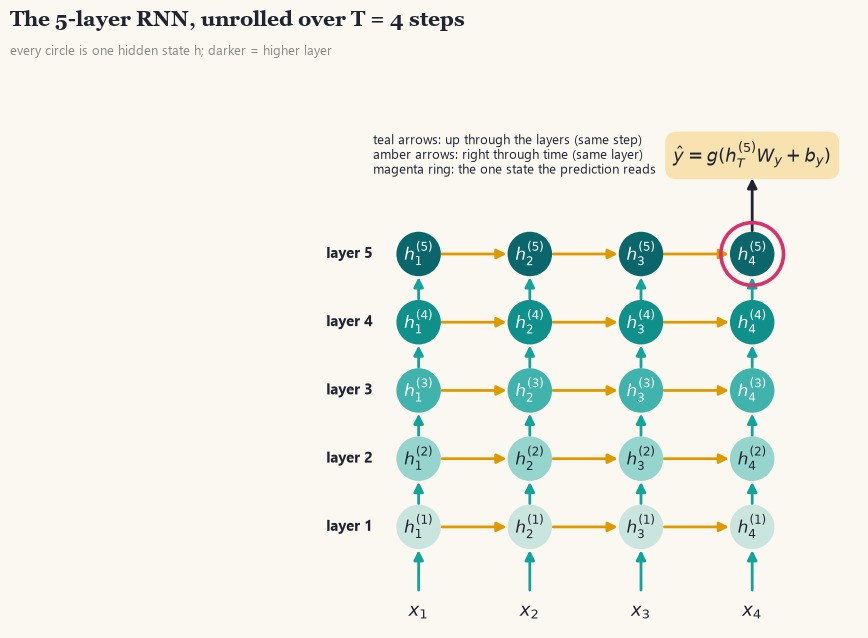

In [6]:
L, T_ = 5, 4
fig, ax = plt.subplots(figsize=(11, 7))
shade = SEQ(np.linspace(0.18, 0.95, L))
for l in range(L):
    for t in range(T_):
        ax.add_patch(Circle((t * 2.2, l * 1.35), 0.44, fc=shade[l], ec="none", zorder=3))
        ax.text(t * 2.2, l * 1.35, f"$h^{{({l + 1})}}_{{{t + 1}}}$", ha="center", va="center", fontsize=12, color="white" if l >= 2 else C["ink"], zorder=4)
        if t < T_ - 1: arrow(ax, (t * 2.2 + 0.46, l * 1.35), (t * 2.2 + 1.74, l * 1.35), TIME, lw=2)
        if l < L - 1: arrow(ax, (t * 2.2, l * 1.35 + 0.46), (t * 2.2, (l + 1) * 1.35 - 0.46), UP, lw=2)
    ax.text(-0.9, l * 1.35, f"layer {l + 1}", ha="right", va="center", fontsize=11, fontweight="bold")
for t in range(T_):
    arrow(ax, (t * 2.2, -1.25), (t * 2.2, -0.46), UP, lw=2); ax.text(t * 2.2, -1.5, f"$x_{{{t + 1}}}$", ha="center", va="top", fontsize=13)
xo = (T_ - 1) * 2.2
arrow(ax, (xo, (L - 1) * 1.35 + 0.46), (xo, L * 1.35 + 0.15), C["ink"], lw=2)
box(ax, xo - 1.7, L * 1.35 + 0.15, 3.4, 0.9, "$\\hat y = g(h^{(5)}_T W_y + b_y)$", C["amb_l"], fs=13)
ax.add_patch(Circle((xo, (L - 1) * 1.35), 0.62, fc="none", ec=C["lstm"], lw=2.6, zorder=5))
ax.text(-0.9, L * 1.35 + 0.6, "teal arrows: up through the layers (same step)\namber arrows: right through time (same layer)\nmagenta ring: the one state the prediction reads", fontsize=9.5, va="center", color=C["ink"])
ax.set_xlim(-2.3, (T_ - 1) * 2.2 + 2.1); ax.set_ylim(-2.0, L * 1.35 + 1.4); ax.set_aspect("equal"); ax.axis("off")
headline(fig, "The 5-layer RNN, unrolled over T = 4 steps", "every circle is one hidden state h; darker = higher layer")
finish(fig, "C_grid")

**Reading the grid.** Every circle is one hidden state, and darker circles belong to higher layers. The teal arrows carry a state up to the next layer at the same step, the amber arrows carry it to the next step within a layer, and the magenta ring marks the only state the prediction reads. The picture makes the cost of depth visible: the prediction at the top right depends on every circle that has a path leading to it, which is the whole grid, and a training signal from the ring has to travel left (through time) and down (through layers) to reach the early inputs.

### The 5-layer RNN by hand (NumPy), checked against PyTorch and Keras

Now we check that the formulas above really are what the libraries compute. We use small sizes so that the numbers stay readable: $F=3$ input features, $H=4$ units, $T=6$ steps, $L=5$ layers and a batch of 2 sequences. The weights are taken from a PyTorch `nn.RNN(3, 4, num_layers=5)` and copied into our hand-written version, which uses only matrix products, additions and tanh, and into a Keras stack of five `SimpleRNN` layers. If all three give the same output, the libraries are doing exactly what we wrote.

Copying weights needs care with the naming conventions. PyTorch stores the transposed input matrix $W_x^\top$ (shape $H\times F$) as `weight_ih_l{k}` and has **two** biases, `bias_ih` and `bias_hh`, whose sum is our $b$; Keras stores $W_x$ (`kernel`, shape $F\times H$), $W_h$ (`recurrent_kernel`) and a single bias.

In [7]:
F, H, T, L, B = 3, 4, 6, 5, 2
torch_rnn = nn.RNN(F, H, num_layers=L, batch_first=True)          # tanh by default
P = {k: v.detach().numpy().astype(np.float64) for k, v in torch_rnn.named_parameters()}
W = [dict(Wx=P[f"weight_ih_l{l}"].T, Wh=P[f"weight_hh_l{l}"].T, b=P[f"bias_ih_l{l}"] + P[f"bias_hh_l{l}"]) for l in range(L)]

def rnn_layer(seq, Wx, Wh, b):
    """f^(l): sequence (B,T,in) -> sequence of states (B,T,H). Only matmul, add, tanh."""
    h = np.zeros((seq.shape[0], Wh.shape[0])); out = []
    for t in range(seq.shape[1]):
        h = np.tanh(seq[:, t] @ Wx + h @ Wh + b)
        out.append(h)
    return np.stack(out, 1)

def rnn_5layer(x):
    seq = x
    for l in range(L):                       # f^(5) ∘ ... ∘ f^(1)
        seq = rnn_layer(seq, **W[l])
    return seq

x = np.random.default_rng(0).normal(size=(B, T, F))
ours = rnn_5layer(x)
pt, _ = torch_rnn(torch.tensor(x, dtype=torch.float32))
km = keras.Sequential([layers.Input((T, F))] + [layers.SimpleRNN(H, return_sequences=True) for _ in range(L)])
for l, lay in enumerate(km.layers):
    lay.set_weights([W[l]["Wx"], W[l]["Wh"], W[l]["b"]])
kr = km(x.astype("float32")).numpy()
print("Top-layer states h^(5)_t of the first sequence, computed by hand (one row per step):\n", ours[0])
print(f"Largest difference between our NumPy version and PyTorch: {np.abs(ours - pt.detach().numpy()).max():.2e}")
print(f"Largest difference between our NumPy version and Keras  : {np.abs(ours - kr).max():.2e}")

Top-layer states h^(5)_t of the first sequence, computed by hand (one row per step):
 [[-0.5281  0.6066 -0.0721  0.3252]
 [-0.4431  0.4689 -0.0764  0.0933]
 [-0.5025  0.5906 -0.0932  0.197 ]
 [-0.4672  0.5651 -0.0562  0.0807]
 [-0.505   0.5967 -0.0782  0.1946]
 [-0.4929  0.5457 -0.047   0.0764]]
Largest difference between our NumPy version and PyTorch: 6.71e-08
Largest difference between our NumPy version and Keras  : 9.17e-08


**Reading the check.** The first block prints the states of the top layer for the first sequence, one row per step. The two lines below it are the verdict: our NumPy composition differs from PyTorch and from Keras by at most about $10^{-7}$. That is the size of single-precision rounding errors (float32 carries about seven decimal digits), so the three implementations compute the same function. The 5-layer RNN is, literally, the composition we wrote down.

### What the five layers hold

The check above compared only the top layer. Drawing every layer's states for the same input sequence shows the stack at work: each row of a panel is one hidden unit, each column one step, the **size** of a dot is how strongly the unit is active, and its **colour** the sign (indigo negative, magenta positive).

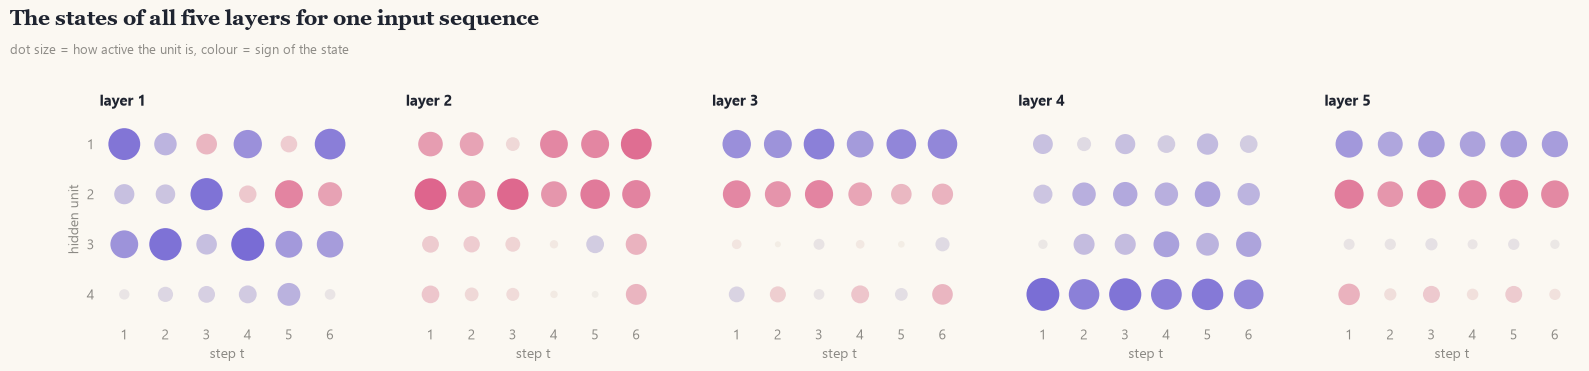

In [8]:
seq, per_layer = x, []
for l in range(L):
    seq = rnn_layer(seq, **W[l]); per_layer.append(seq[0])
fig, ax = plt.subplots(1, L, figsize=(16, 3.6), sharey=True)
for l, a in enumerate(ax):
    hh = per_layer[l]
    tt, uu = np.meshgrid(np.arange(T), np.arange(H), indexing="ij")
    a.scatter(tt.ravel(), uu.ravel(), s=700 * np.abs(hh).ravel() + 12, c=hh.ravel(), cmap=DIV, vmin=-1, vmax=1, edgecolor="none")
    a.set_title(f"layer {l + 1}"); a.set_xticks(range(T), range(1, T + 1)); a.set_xlabel("step t"); a.set_xlim(-0.6, T - 0.4); a.set_ylim(H - 0.4, -0.6)
ax[0].set_ylabel("hidden unit"); ax[0].set_yticks(range(H), range(1, H + 1))
headline(fig, "The states of all five layers for one input sequence", "dot size = how active the unit is, colour = sign of the state")
finish(fig, "C_states")

**Reading the dot matrices.** In layer 1 the dots change from step to step: this layer sees the raw input, and the input changes. In the higher layers the pattern becomes calmer: in layers 4 and 5 most units keep nearly the same value over all six steps. The states of these layers are summaries of what the layers below have already processed, so they move more slowly than the input. (With random, untrained weights this smoothing is only a tendency, and a trained network would use it to form its features, but it shows how the layers differ.)

### Parameters of a 5-layer RNN

The parameters are the numbers that training adjusts, so counting them tells us how large the model is. Layer 1 maps $F\to H$, layers 2–5 map $H\to H$:

$$\underbrace{FH+H^2+H}_{\text{layer 1}}+\underbrace{4\,(H^2+H^2+H)}_{\text{layers 2–5}}+\underbrace{H+1}_{\text{head}} .$$

For $F=3$, $H=4$ this is $(12+16+4)+4(16+16+4)+5=32+144+5=181$. Where does each term come from? $W_x$ has $F\times H$ numbers because each of the $H$ units has one weight per input feature; for layers 2–5 the inputs are the $H$ states of the layer below, so the matrix is $H\times H$. $W_h$ has $H\times H$ numbers because each unit looks at the previous state of **all** $H$ units of its layer, its own included. The bias adds one number per unit, and the output head maps $H$ numbers to one output ($H$ weights and one bias). Note that the count does not depend on $T$: a review of 10 words and one of 100 words use the same weights.

PyTorch's count is larger by $L\cdot H=20$. It keeps the two bias vectors `bias_ih` and `bias_hh` separately (a convention inherited from the cuDNN library). Only their sum enters the formula, so the model is identical; it just stores $H$ extra numbers per layer.

In [9]:
def rnn_params(F, H, L, two_bias=False):
    first = F * H + H * H + H * (2 if two_bias else 1)
    rest = (L - 1) * (H * H + H * H + H * (2 if two_bias else 1))
    return first + rest + H + 1
print("Our formula (one bias per layer)    :", rnn_params(F, H, L))
print("Keras: five SimpleRNN layers + head :", km.count_params(), "+", H + 1, "=", km.count_params() + H + 1)
print("PyTorch: nn.RNN + head              :", sum(p.numel() for p in torch_rnn.parameters()) + H + 1, "(our formula with two biases gives", rnn_params(F, H, L, True), ")")

Our formula (one bias per layer)    : 181
Keras: five SimpleRNN layers + head : 176 + 5 = 181
PyTorch: nn.RNN + head              : 201 (our formula with two biases gives 201 )


**Reading the counts.** Our formula gives 181, the Keras stack (176 numbers for the five layers plus 5 for the head) gives 181, and PyTorch gives 201, which is exactly the formula with two biases ($181+20$). All three agree where they should.

## 4. Why depth and length hurt a plain RNN: the gradient

Training a network means asking, for every weight, "if I made this weight a little larger, would the loss go up or down, and by how much?". The answer is the **gradient** of the loss with respect to the weight, and it is computed by the chain rule, from the loss backwards through every function that was applied. For the weights that act on the first words of a review, the chain is long: it runs through all the steps between the first word and the last.

**The gradient is a product.** With $h_t=\tanh(a_t)$ and $a_t=x_tW_x+h_{t-1}W_h+b$, going back one step in time multiplies the gradient by a matrix, and going back $T-t$ steps multiplies it by $T-t$ such matrices:

$$\frac{\partial h_t}{\partial h_{t-1}}=\underbrace{\mathrm{diag}(1-h_t^2)}_{\tanh'}\;W_h^\top ,\qquad
\frac{\partial h_T}{\partial h_{t}}=\prod_{k=t+1}^{T}\mathrm{diag}(1-h_k^2)\,W_h^\top .$$

Going down one layer multiplies by a similar factor with $W_x$ in place of $W_h$, so coming from layer 5 to layer 1 adds four more factors.

**Why it vanishes.** Every factor contains $1-h^2\le1$, and with typical initial weights each step shrinks the signal a little. A scalar picture: if each step multiplies the gradient by 0.6, then after 50 steps only $0.6^{50}\approx8\times10^{-12}$ is left. If instead each step multiplies by 1.2 the gradient explodes: $1.2^{50}\approx9{,}100$.

**Why it matters.** The update of a weight is proportional to its gradient. If the gradient reaching the first words of a review is $10^{-11}$, those words teach the network nothing, and the RNN effectively learns only from the last few steps, even if the decisive word came early. Explosion can be handled by *gradient clipping* (we clip at norm 1 in the dataset notebooks). Vanishing cannot be clipped away; it needs a different cell, the LSTM.

The experiment below measures this directly. We build a freshly initialised 5-layer RNN, put the loss on the last step of the top layer ($T=50$, $H=32$), and record how large the gradient is at every layer and every step.

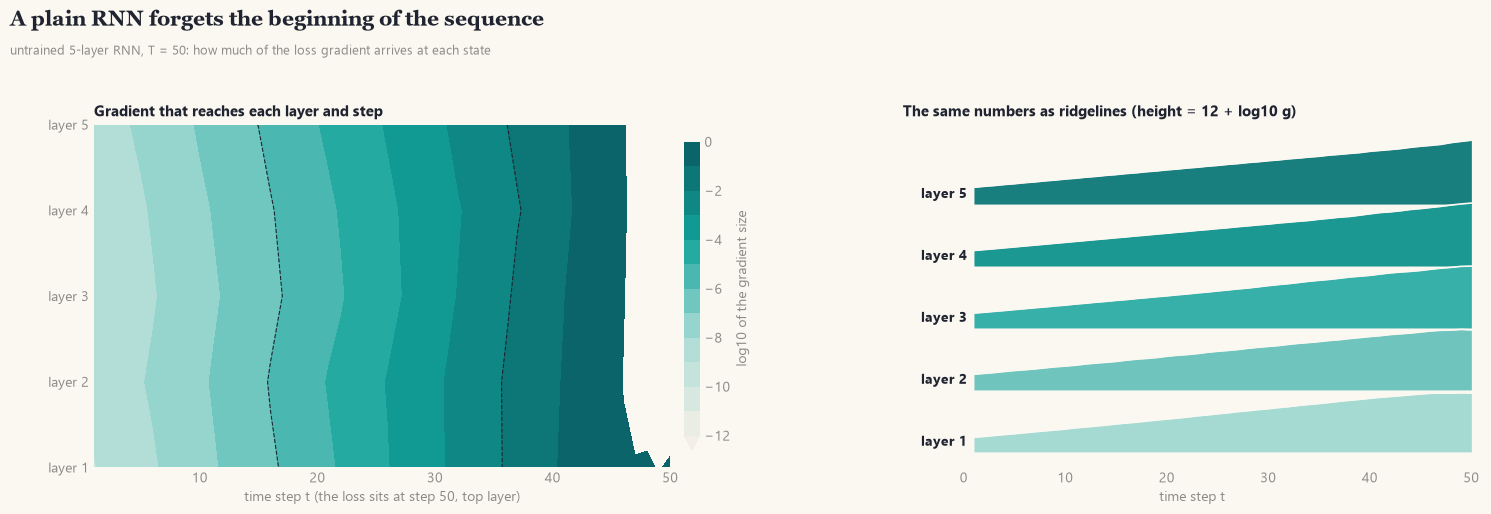

Size of the gradient that reaches step 1, layer by layer (layer 1 first): ['9.1e-10', '1.6e-09', '1.1e-09', '1.4e-09', '2.6e-09']
Step 1 of layer 1 receives only 8.7e-11 of the gradient found at the top-right corner (the loss).


In [10]:
def grad_map(kind, T=50, F=8, H=32, L=5, seed=0, forget_bias=1.0):
    """Unroll a 5-layer RNN/LSTM step by step with cells, so every h^(l)_t is on the gradient path.
    Loss = squared norm of the top layer's last state. Returns ||dL/dh^(l)_t|| as an (L, T) array."""
    torch.manual_seed(seed)
    cells = [(nn.RNNCell if kind == "RNN" else nn.LSTMCell)(F if l == 0 else H, H) for l in range(L)]
    if kind == "LSTM":                       # forget-gate bias (rows H..2H); Keras uses 1, PyTorch's default is 0
        for c in cells:
            c.bias_ih.data[H:2 * H] = forget_bias; c.bias_hh.data[H:2 * H] = 0.0
    x = torch.randn(16, T, F)
    hs, state = [[None] * T for _ in range(L)], [None] * L
    for t in range(T):
        inp = x[:, t]
        for l in range(L):
            out = cells[l](inp, state[l])
            state[l] = out
            h = out if kind == "RNN" else out[0]
            h.retain_grad(); hs[l][t] = h; inp = h
    hs[-1][-1].pow(2).sum().backward()
    return np.array([[hs[l][t].grad.norm().item() for t in range(T)] for l in range(L)])

g_rnn = grad_map("RNN")
n_steps = g_rnn.shape[1]; levels = np.arange(-12, 1, 1)
fig = plt.figure(figsize=(15, 5.2)); gs = fig.add_gridspec(1, 2, width_ratios=[1.2, 1], wspace=0.18)
a = fig.add_subplot(gs[0])
cs = a.contourf(np.arange(1, n_steps + 1), np.arange(5), np.log10(g_rnn + 1e-30), levels=levels, cmap=SEQ, extend="min")
a.contour(np.arange(1, n_steps + 1), np.arange(5), np.log10(g_rnn + 1e-30), levels=[-10, -6, -2], colors=C["ink"], linewidths=0.8)
cb = fig.colorbar(cs, ax=a, pad=0.02, shrink=0.9); cb.set_label("log10 of the gradient size", color=C["mute"]); cb.outline.set_visible(False)
a.set_yticks(range(5), [f"layer {l + 1}" for l in range(5)]); a.set_xlabel("time step t (the loss sits at step 50, top layer)"); a.set_title("Gradient that reaches each layer and step")
b = fig.add_subplot(gs[1])
for l in range(5):
    v = np.clip(np.log10(g_rnn[l] + 1e-30) + 12, 0, None) / 12 * 0.95
    b.fill_between(np.arange(1, n_steps + 1), l, l + v, color=SEQ(0.35 + 0.13 * l), alpha=0.95, lw=0, zorder=10 - l); b.plot(np.arange(1, n_steps + 1), l + v, color=C["paper"], lw=1.2, zorder=10 - l)
    b.text(0.3, l + 0.05, f"layer {l + 1}", ha="right", va="bottom", fontweight="bold")
b.set_yticks([]); b.set_xlim(-6, n_steps + 1); b.set_xlabel("time step t"); b.set_title("The same numbers as ridgelines (height = 12 + log10 g)")
headline(fig, "A plain RNN forgets the beginning of the sequence", "untrained 5-layer RNN, T = 50: how much of the loss gradient arrives at each state")
finish(fig, "C_rnn_grad", top_in=1.2)
print("Size of the gradient that reaches step 1, layer by layer (layer 1 first):", ["%.1e" % v for v in g_rnn[:, 0]])
print("Step 1 of layer 1 receives only %.1e of the gradient found at the top-right corner (the loss)." % (g_rnn[0, 0] / g_rnn[-1, -1]))

**Reading the gradient map.** The left picture is a map of the gradient (darker = more gradient arrives, on a logarithmic scale) and the right one shows the same numbers as one ridgeline per layer. Looking at it, we can see that the gradient is strongest at the last steps on the right, close to the loss, and falls off steadily towards the left: the signal reaching step 1 is about ten orders of magnitude weaker than at the loss. The printout makes this exact: the first step of layer 1 receives only $8.7\cdot10^{-11}$ of the gradient at the top-right corner. Per step this is a factor of about 0.62, close to the scalar example of 0.6 above. The layers behave alike because each layer repeats the same kind of shrinking. A network trained with such gradients could not learn that a word at step 1 matters for the answer at step 50.

## 5. The LSTM cell: gates built from the same elementary functions

The previous section found the problem: the memory of an RNN is *rewritten* at every step (the whole state passes through a matrix and a tanh), so information and gradient both fade. The idea of the LSTM is to give the network a second state, the **cell** $c_t$, that is *not* rewritten but only **edited**: old content can be kept, new content added, and the cell contents shown or hidden, all under the control of learned **gates**. A gate is a number between 0 and 1 for each unit (it is computed with a sigmoid) that says how much of something passes. Each gate is the RNN formula with a sigmoid instead of tanh:

| | Formula | Role |
|---|---|---|
| input gate | $i_t=\sigma(x_tW_i+h_{t-1}U_i+b_i)$ | how much new content to write |
| forget gate | $f_t=\sigma(x_tW_f+h_{t-1}U_f+b_f)$ | how much of the old cell to keep |
| candidate | $g_t=\tanh(x_tW_g+h_{t-1}U_g+b_g)$ | the new content |
| output gate | $o_t=\sigma(x_tW_o+h_{t-1}U_o+b_o)$ | how much of the cell to show |
| cell | $c_t=f_t\odot c_{t-1}+i_t\odot g_t$ | memory, updated by **addition** |
| hidden | $h_t=o_t\odot\tanh(c_t)$ | output of the step |

Composition view: $(h_t,c_t)=\mathrm{LSTM}(x_t,h_{t-1},c_{t-1})$ uses matrix products, additions, sigmoid, tanh and $\odot$ and nothing else.

**A small example.** Take $f=0.9$, $c_{t-1}=2.0$, $i=0.5$, $g=0.6$. Then $c_t=0.9\cdot2.0+0.5\cdot0.6=1.8+0.3=2.1$: the cell keeps 90 % of what it had and adds half of the new content.

**Why each piece is there.**

- *The gates see $x_t$ and $h_{t-1}$.* The decision to forget or write depends on context. After reading "not", the network should treat the following "good" differently, and only $h_{t-1}$ knows that "not" came before.
- *The candidate uses tanh.* New content can push a memory up or down, so it needs signed values in $(-1,1)$, just like the RNN state.
- *The gates use sigmoid.* They are fractions, as argued in §1.
- *The cell is updated by addition.* In $c_t=f_t\odot c_{t-1}+i_t\odot g_t$ the old memory is **copied** (scaled by $f_t$) and not pushed through a matrix and a tanh again. This changes the gradient completely. Going back one step along the cell gives

$$\frac{\partial c_t}{\partial c_{t-1}}=\mathrm{diag}(f_t)\quad(\text{plus small indirect terms}),$$

 so the gradient is multiplied by the forget gate only, with no weight matrix and no squashing derivative. If $f\approx0.97$, then over 50 steps $0.97^{50}\approx0.22$ survives, against $0.6^{50}\approx8\times10^{-12}$ for the RNN of §4, ten orders of magnitude more.
- *$h_t=o_t\odot\tanh(c_t)$.* The cell is a sum, so it can grow beyond 1, and tanh brings the output back into $(-1,1)$ for the next layer. The output gate lets the cell **hold** information without showing it until it is useful: a word read at step 5 can be released at step 90.
- *Nobody sets the gates by hand.* Training adjusts $W_f,U_f,b_f$ (and the others) so that $f_t\approx1$ where memory is useful (an early "but" that flips the meaning of a review) and $f_t\approx0$ where the cell should reset.

In [11]:
def lstm_step(xt, h, c, Wk, Uk, bk):
    """One LSTM step from elementary functions. Wk, Uk, bk are dicts with keys i, f, g, o."""
    z = {k: xt @ Wk[k] + h @ Uk[k] + bk[k] for k in "ifgo"}            # four affine maps
    i, f, o = sigmoid(z["i"]), sigmoid(z["f"]), sigmoid(z["o"])        # gates in (0,1)
    g = np.tanh(z["g"])                                                # candidate in (-1,1)
    c = f * c + i * g                                                  # ⊙ and +
    h = o * np.tanh(c)
    return h, c, dict(i=i, f=f, g=g, o=o)

rng = np.random.default_rng(1)
Wk = {k: rng.normal(scale=0.5, size=(2, 2)) for k in "ifgo"}; Uk = {k: rng.normal(scale=0.5, size=(2, 2)) for k in "ifgo"}
bk = {k: np.zeros(2) for k in "ifgo"}; bk["f"] = np.ones(2)                # forget bias 1: start by remembering
h = c = np.zeros(2)
for t, xt in enumerate(xs, 1):
    h, c, gates = lstm_step(xt, h, c, Wk, Uk, bk)
    print(f"step {t}: forget gate f={gates['f']}, input gate i={gates['i']}, output gate o={gates['o']}  ->  cell c={c}, hidden h={h}")

step 1: forget gate f=[0.8104 0.7726], input gate i=[0.5431 0.6013], output gate o=[0.409  0.4796]  ->  cell c=[0.0979 0.0878], hidden h=[0.0399 0.042 ]
step 2: forget gate f=[0.7281 0.805 ], input gate i=[0.5587 0.3876], output gate o=[0.407  0.5596]  ->  cell c=[0.0979 0.1837], hidden h=[0.0397 0.1017]
step 3: forget gate f=[0.7916 0.6803], input gate i=[0.4491 0.6531], output gate o=[0.5873 0.413 ]  ->  cell c=[ 0.043  -0.0844], hidden h=[ 0.0252 -0.0348]


**Following the numbers.** The code implements one LSTM step with only the elementary functions (four affine maps, three sigmoids, one tanh, two $\odot$ and one addition) and runs it on the same three inputs as the RNN example. Because the forget bias starts at 1, the forget gates are around 0.7–0.8 (their pre-activation is near 1 and $\sigma(1)=0.73$), so the cell keeps most of its contents at every step, while the input gates, near 0.4–0.65, let in about half of the new content. The cell values $c$ stay small here because the toy weights are small. The hidden state $h$ is smaller still, since it is the cell scaled by the output gate (0.4–0.6) after a tanh.

### The LSTM cell as a picture

The same equations, drawn as the path data takes. The **top line is the cell state** $c$, the memory highway: it runs through the cell with only one multiplication (by the forget gate) and one addition (of the new content). Everything under the line is gate machinery that reads $[h_{t-1},x_t]$ and decides what happens on the highway: the left gate scales the old memory, the middle gates decide what is added, and the right gate decides how much of the memory is shown as the output $h_t$.

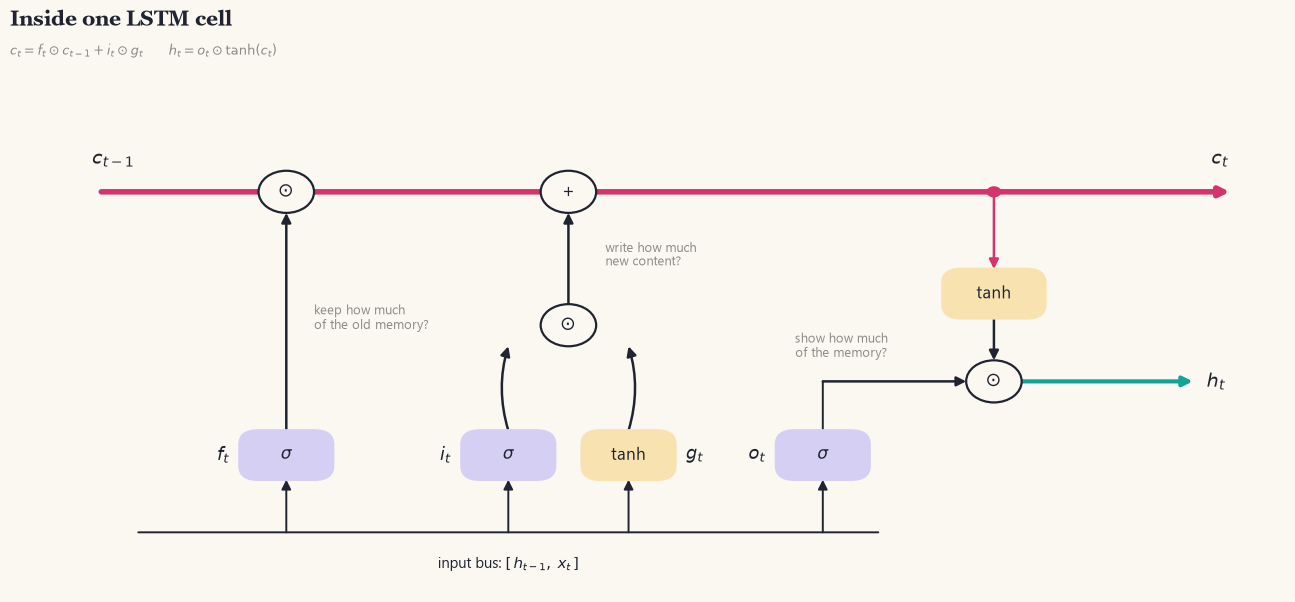

In [12]:
fig, ax = plt.subplots(figsize=(13, 6.6)); ax.set_xlim(0, 13); ax.set_ylim(-0.4, 6.4); ax.axis("off")
def op(x, y, s):
    ax.add_patch(Circle((x, y), 0.3, fc=C["paper"], ec=C["ink"], lw=1.6, zorder=3)); ax.text(x, y, s, ha="center", va="center", fontsize=14, zorder=4)
CY = 5.3                                                                  # height of the cell-state highway
arrow(ax, (0.2, CY), (12.4, CY), C["lstm"], lw=4); ax.text(0.1, CY + 0.4, "$c_{t-1}$", fontsize=14); ax.text(12.2, CY + 0.4, "$c_t$", fontsize=14)
fx, ix, gx, ox = 2.2, 4.6, 5.9, 8.0                                       # gate centres
for xc, label, fc, name in [(fx, "$\\sigma$", C["ind_l"], "$f_t$"), (ix, "$\\sigma$", C["ind_l"], "$i_t$"), (gx, "tanh", C["amb_l"], "$g_t$"), (ox, "$\\sigma$", C["ind_l"], "$o_t$")]:
    box(ax, xc - 0.5, 1.2, 1.0, 0.7, label, fc, fs=12, zorder=3)
    ax.text(xc + 0.62 if name == "$g_t$" else xc - 0.62, 1.55, name, ha="left" if name == "$g_t$" else "right", va="center", fontsize=13)
    arrow(ax, (xc, 0.45), (xc, 1.2), C["ink"], lw=1.4)
arrow(ax, (0.6, 0.45), (8.6, 0.45), C["ink"], lw=1.4, style="-"); ax.text(4.6, 0.1, "input bus: $[\\,h_{t-1},\\;x_t\\,]$", ha="center", va="top", fontsize=10.5)
op(fx, CY, "$\\odot$"); arrow(ax, (fx, 1.9), (fx, CY - 0.3), C["ink"]); ax.text(fx + 0.3, 3.5, "keep how much\nof the old memory?", fontsize=9, va="center", color=C["mute"])
op((ix + gx) / 2, 3.4, "$\\odot$"); arrow(ax, (ix, 1.9), (ix, 3.1), C["ink"], rad=-0.15); arrow(ax, (gx, 1.9), (gx, 3.1), C["ink"], rad=0.15)
op((ix + gx) / 2, CY, "+"); arrow(ax, ((ix + gx) / 2, 3.7), ((ix + gx) / 2, CY - 0.3), C["ink"]); ax.text((ix + gx) / 2 + 0.4, 4.4, "write how much\nnew content?", fontsize=9, va="center", color=C["mute"])
box(ax, 9.3, 3.5, 1.1, 0.7, "tanh", C["amb_l"], fs=12, zorder=3); arrow(ax, (9.85, CY), (9.85, 4.2), C["lstm"]); ax.add_patch(Circle((9.85, CY), 0.08, fc=C["lstm"], zorder=4))
op(9.85, 2.6, "$\\odot$"); arrow(ax, (9.85, 3.5), (9.85, 2.9), C["ink"]); arrow(ax, (ox, 1.9), (ox, 2.6), C["ink"], lw=1.4, style="-"); arrow(ax, (ox, 2.6), (9.55, 2.6), C["ink"])
ax.text(8.2, 3.1, "show how much\nof the memory?", fontsize=9, va="center", ha="center", color=C["mute"])
arrow(ax, (10.15, 2.6), (12.0, 2.6), C["rnn"], lw=3); ax.text(12.15, 2.6, "$h_t$", fontsize=14, va="center")
headline(fig, "Inside one LSTM cell", r"$c_t = f_t \odot c_{t-1} + i_t \odot g_t \qquad h_t = o_t \odot \tanh(c_t)$")
finish(fig, "C_lstm_cell")

### Gates in action (hand-set illustration)

To see *what the gates are for*, we set them by hand on a tiny memory task. A value $+1$ is written into the cell at step 3 and must still be readable at step 20, seventeen steps later. This is **not** a trained network; it only shows the cell equation $c_t=f_t\odot c_{t-1}+i_t\odot g_t$ at work. The right panel keeps the write at step 3 and varies only the forget gate. The values $0.5$ and $0.73$ are $\sigma(0)$ and $\sigma(1)$, the forget gates a freshly initialised LSTM starts with (bias 0 and bias 1), and $0.97$ is what a trained gate can learn to be on a "remember this" step.

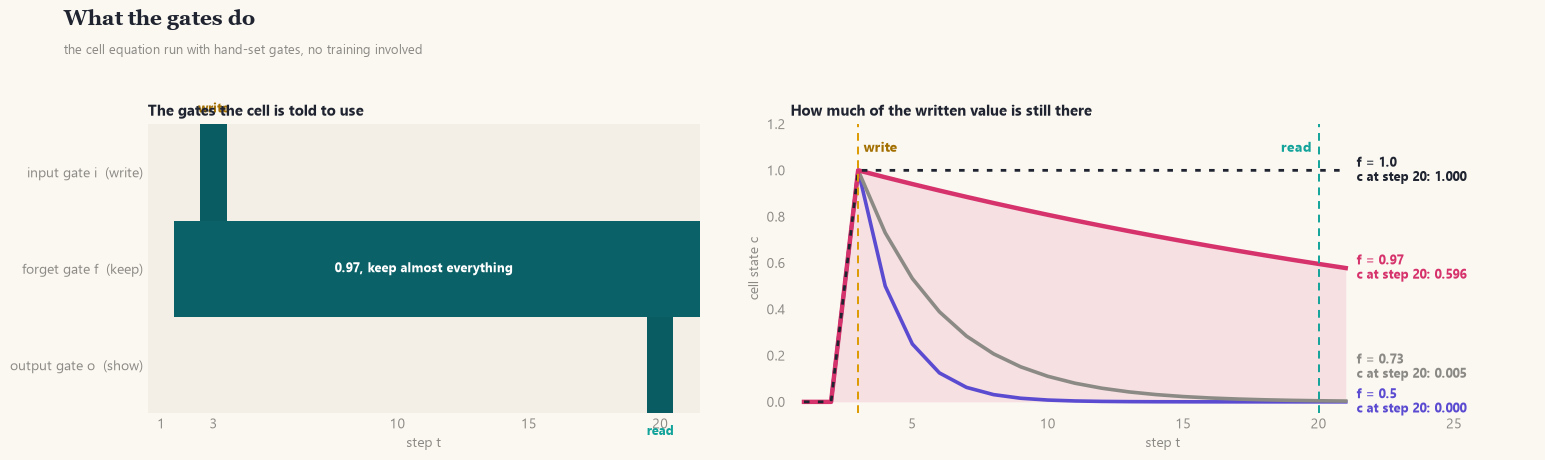

Share of the written value that is left after 17 steps, for each forget-gate value: {0.5: 0.0, 0.73: 0.0047, 0.97: 0.5958, 1.0: 1.0}


In [13]:
Tn = 21; write_at, read_at = 3, 20
def run_cell(f_hold):
    c, trace = 0.0, []
    for t in range(1, Tn + 1):
        i = 1.0 if t == write_at else 0.0                     # open the input gate once
        f = 0.0 if t == 1 else f_hold                         # nothing to remember before the write
        c = f * c + i * 1.0                                   # candidate content g = +1
        trace.append(c)
    return np.array(trace)
tt = np.arange(1, Tn + 1)
gate_rows = np.array([[1.0 if t == write_at else 0.0 for t in tt], [0.97 if t > 1 else 0.0 for t in tt], [1.0 if t == read_at else 0.0 for t in tt]])
fig = plt.figure(figsize=(15, 4.6)); gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.35], wspace=0.14)
a = fig.add_subplot(gs[0]); a.imshow(gate_rows, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
a.text(write_at - 1, -0.62, "write", ha="center", fontsize=9, fontweight="bold", color="#a36f00"); a.text(read_at - 1, 2.62, "read", ha="center", va="top", fontsize=9, fontweight="bold", color=C["rnn"])
a.text(Tn / 2 - 0.5, 1, "0.97, keep almost everything", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
a.set_yticks(range(3), ["input gate i  (write)", "forget gate f  (keep)", "output gate o  (show)"]); a.set_xticks([0, write_at - 1, 9, 14, read_at - 1], [1, write_at, 10, 15, read_at]); a.set_xlabel("step t")
a.set_title("The gates the cell is told to use")
b = fig.add_subplot(gs[1])
for fh, col, ls, lw in [(0.5, C["neg"], "-", 2.6), (0.73, C["mute"], "-", 2.6), (0.97, C["lstm"], "-", 3.2), (1.0, C["ink"], (0, (2, 3)), 2.0)]:
    tr = run_cell(fh); b.plot(tt, tr, color=col, ls=ls, lw=lw)
    if fh == 0.97: b.fill_between(tt, tr, color=col, alpha=0.12, lw=0)
    b.text(Tn + 0.4, {0.5: 0.0, 0.73: 0.15}.get(fh, tr[-1]), f"f = {fh}\nc at step {read_at}: {tr[read_at - 1]:.3f}", color=col, va="center", fontsize=9, fontweight="bold")
b.axvline(write_at, color=C["pos"], ls=(0, (4, 3)), lw=1.4); b.axvline(read_at, color=C["rnn"], ls=(0, (4, 3)), lw=1.4)
b.text(write_at + 0.2, 1.08, "write", color="#a36f00", fontweight="bold"); b.text(read_at - 0.25, 1.08, "read", color=C["rnn"], fontweight="bold", ha="right")
b.set_xlim(0.5, Tn + 7); b.set_ylim(-0.05, 1.2); b.set_xlabel("step t"); b.set_ylabel("cell state c"); b.set_title("How much of the written value is still there")
headline(fig, "What the gates do", "the cell equation run with hand-set gates, no training involved")
finish(fig, "C_gates", top_in=1.2)
print("Share of the written value that is left after %d steps, for each forget-gate value:" % (read_at - write_at), {f: round(float(f ** (read_at - write_at)), 4) for f in (0.5, 0.73, 0.97, 1.0)})

**Reading the gate picture.** Writing is done by briefly opening the input gate (step 3) and reading by opening the output gate (step 20); in between the forget gate stays high so that the memory is not erased. The right-hand curves show why the forget gate is the key number. With $f=1$ nothing is ever lost. With $f=0.97$ the value decays slowly and 60 % of it (0.596) is still there after 17 steps. With $f=0.73$, the value a freshly initialised LSTM has when the forget bias is 1, only 0.5 % (0.0047) is left, and with $f=0.5$ (bias 0) practically nothing, $0.5^{17}\approx8\cdot10^{-6}$. An LSTM cannot remember a value for long unless its forget gate learns to be close to 1; the architecture makes that possible, but training still has to find it.

### The 5-layer LSTM by hand, checked against PyTorch and Keras

Stacking works exactly as for the RNN: layer $l$ reads the hidden states $h^{(l-1)}_t$ of the layer below, and every layer has its own cell state $c^{(l)}_t$. Both frameworks store the four gates side by side in one matrix of width $4H$, in the order **i, f, g, o** (Keras calls the candidate $g$ "c"); PyTorch again keeps two biases.

**Why one matrix of width $4H$?** All four gates read the same inputs $(x_t,h_{t-1})$. Concatenating their weights turns four small matrix products into one large one, which a processor computes faster, and the result is then split into four blocks of $H$ columns. The order **i, f, g, o** is only a storage convention, but it must match when weights are copied between frameworks, which is why the code below copies block by block.

In [14]:
torch_lstm = nn.LSTM(F, H, num_layers=L, batch_first=True)
P = {k: v.detach().numpy().astype(np.float64) for k, v in torch_lstm.named_parameters()}
def split4(M): return dict(zip("ifgo", np.split(M, 4, axis=-1)))
WL = [dict(W=split4(P[f"weight_ih_l{l}"].T), U=split4(P[f"weight_hh_l{l}"].T), b=split4(P[f"bias_ih_l{l}"] + P[f"bias_hh_l{l}"])) for l in range(L)]

def lstm_5layer(x):
    seq = x
    for l in range(L):
        h = np.zeros((x.shape[0], H)); c = np.zeros_like(h); out = []
        for t in range(seq.shape[1]):
            h, c, _ = lstm_step(seq[:, t], h, c, WL[l]["W"], WL[l]["U"], WL[l]["b"])
            out.append(h)
        seq = np.stack(out, 1)
    return seq

ours = lstm_5layer(x)
pt, _ = torch_lstm(torch.tensor(x, dtype=torch.float32))
kl = keras.Sequential([layers.Input((T, F))] + [layers.LSTM(H, return_sequences=True) for _ in range(L)])
for l, lay in enumerate(kl.layers):
    lay.set_weights([P[f"weight_ih_l{l}"].T, P[f"weight_hh_l{l}"].T, P[f"bias_ih_l{l}"] + P[f"bias_hh_l{l}"]])
print(f"Largest difference between our NumPy LSTM and PyTorch: {np.abs(ours - pt.detach().numpy()).max():.2e}")
print(f"Largest difference between our NumPy LSTM and Keras  : {np.abs(ours - kl(x.astype('float32')).numpy()).max():.2e}")

Largest difference between our NumPy LSTM and PyTorch: 4.56e-08
Largest difference between our NumPy LSTM and Keras  : 8.02e-08


**Reading the check.** As for the RNN, the hand-written 5-layer LSTM agrees with PyTorch and with Keras up to float32 rounding (differences of about $10^{-8}$ to $10^{-7}$), so the gates, the cell update and the stacking written above are exactly what the libraries compute.

### Parameters of a 5-layer LSTM

Each layer has four copies of the RNN's weights, one per gate:

$$4(FH+H^2+H)+4\cdot4(H^2+H^2+H)+H+1 .$$

For $F=3$, $H=4$ this is $4\cdot32+4\cdot4\cdot36+5=128+576+5=709$, about four times the RNN's 181. **Why exactly 4×?** Each of the four blocks (i, f, g, o) has the same shape as one RNN layer: an input matrix, a recurrent matrix and a bias. The cell update $c_t=f\odot c_{t-1}+i\odot g$ and the output $h_t=o\odot\tanh c_t$ add no parameters, because they only combine the four results with $\odot$ and $+$.

**What it costs.** Each step does four times the matrix work of an RNN step, so an LSTM epoch takes noticeably longer. The extra parameters buy controlled memory, not simply a bigger model of the same kind. In the dataset notebooks the RNN is deliberately *not* given four times more units to compensate, because then the comparison would change the size and the architecture at the same time.

In [15]:
def lstm_params(F, H, L, two_bias=False):
    nb = 2 if two_bias else 1
    return 4 * (F * H + H * H + nb * H) + (L - 1) * 4 * (2 * H * H + nb * H) + H + 1
print("Our formula (one bias per layer)    :", lstm_params(F, H, L), "   Keras: five LSTM layers + head :", kl.count_params() + H + 1)
print("PyTorch: nn.LSTM + head              :", sum(p.numel() for p in torch_lstm.parameters()) + H + 1, "(our formula with two biases gives", lstm_params(F, H, L, True), ")")
print("\nSizes used in the dataset notebooks (5 recurrent layers):")
print(f"  reviews, input = 64-d word embedding, H = 64: RNN {rnn_params(64, 64, 5):,}  LSTM {lstm_params(64, 64, 5):,}  (+ embedding 20,000 x 64)")
print(f"  stocks,  input = 4 features,          H = 32: RNN {rnn_params(4, 32, 5):,}  LSTM {lstm_params(4, 32, 5):,}")

Our formula (one bias per layer)    : 709    Keras: five LSTM layers + head : 709
PyTorch: nn.LSTM + head              : 789 (our formula with two biases gives 789 )

Sizes used in the dataset notebooks (5 recurrent layers):
  reviews, input = 64-d word embedding, H = 64: RNN 41,345  LSTM 165,185  (+ embedding 20,000 x 64)
  stocks,  input = 4 features,          H = 32: RNN 9,537  LSTM 38,049


**Reading the counts.** The formula (709) matches the Keras count and the PyTorch count with two biases (789). The last two lines give the sizes used in the dataset notebooks. For the reviews (input = 64-dimensional word embedding, $H=64$) the five recurrent layers hold 41,345 numbers in the RNN and 165,185 in the LSTM, but the embedding table of $20{,}000\times64$ adds 1.28 million to both, so the LSTM makes the whole model only 9 % larger. For the stocks (4 input features, $H=32$) there is no embedding, and the LSTM really has four times as many parameters (38,049 against 9,537).

## 6. Gradient flow: LSTM against RNN

We repeat the experiment of §4 for a 5-layer LSTM with two settings of the **forget-gate bias**. The bias $b_f$ is the number added to the forget gate's pre-activation, so it sets how much the gate lets through at the beginning of training, before the weights have learned anything: $f\approx\sigma(b_f)$. Keras starts with bias 1 ($f\approx\sigma(1)=0.73$), PyTorch with bias 0 ($f\approx\sigma(0)=0.5$). The dataset notebooks therefore set the bias to 1 in PyTorch too, so that both frameworks start alike.

**Why bias 1 helps.** At the start of training the gradient that passes back through the cell is roughly $f^{T}$ for $T$ steps:

- bias 0: $\sigma(0)=0.5$ and $0.5^{50}\approx9\times10^{-16}$. The cell starts out forgetting almost everything, and the gradient vanishes as badly as in the RNN;
- bias 1: $\sigma(1)=0.73$ and $0.73^{50}\approx1.5\times10^{-7}$, about $10^{8}$ times larger. Training then has a signal to push $f$ toward 1 where memory pays off.

The principle is to start the network *remembering* and let it learn what to forget. If it starts out forgetting, it can never discover what was worth remembering, because no gradient reaches the early steps to tell it.

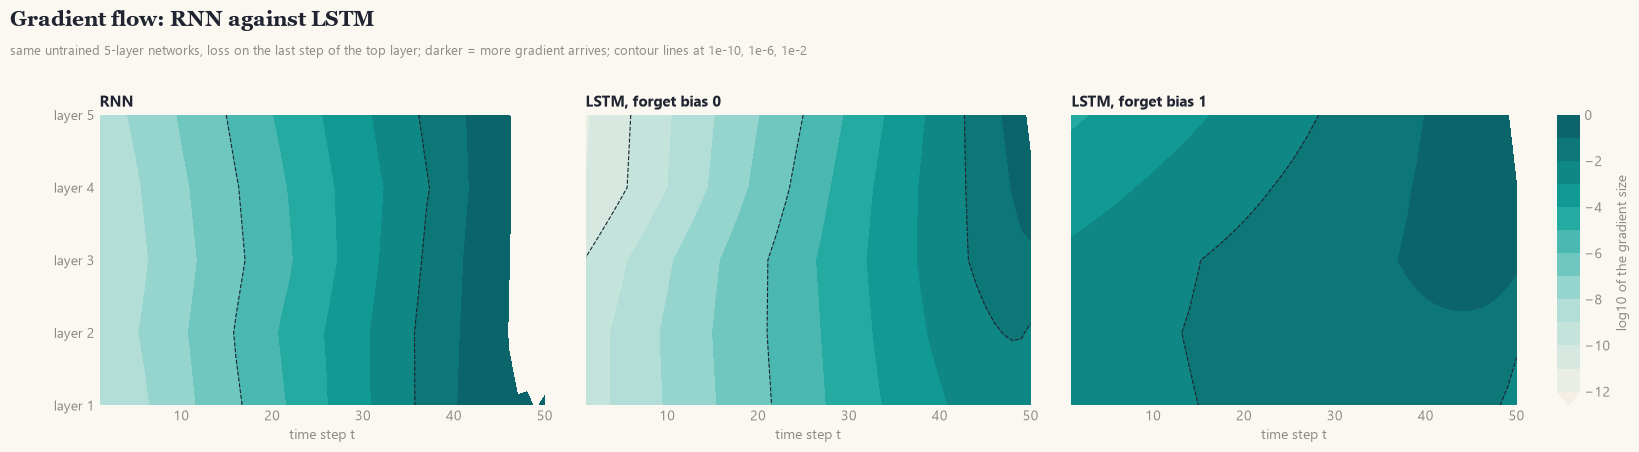

RNN                   : step 1 of layer 1 receives 8.7e-11 of the gradient at the loss
LSTM, forget bias 0   : step 1 of layer 1 receives 9.4e-11 of the gradient at the loss
LSTM, forget bias 1   : step 1 of layer 1 receives 4.5e-04 of the gradient at the loss


In [16]:
g_lstm = grad_map("LSTM", forget_bias=1.0)
g_lstm0 = grad_map("LSTM", forget_bias=0.0)
maps = [(g_rnn, "RNN"), (g_lstm0, "LSTM, forget bias 0"), (g_lstm, "LSTM, forget bias 1")]
fig = plt.figure(figsize=(16, 4.5)); gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 0.05], wspace=0.12)
ax = [fig.add_subplot(gs[0, 0])]; ax += [fig.add_subplot(gs[0, j], sharey=ax[0]) for j in (1, 2)]
for a, (g, name) in zip(ax, maps):
    cs = a.contourf(np.arange(1, g.shape[1] + 1), np.arange(5), np.log10(g + 1e-30), levels=np.arange(-12, 1, 1), cmap=SEQ, extend="min")
    a.contour(np.arange(1, g.shape[1] + 1), np.arange(5), np.log10(g + 1e-30), levels=[-10, -6, -2], colors=C["ink"], linewidths=0.8)
    a.set_title(name); a.set_xlabel("time step t")
ax[0].set_yticks(range(5), [f"layer {l + 1}" for l in range(5)])
for a in ax[1:]: a.tick_params(labelleft=False)
cb = fig.colorbar(cs, cax=fig.add_subplot(gs[0, 3])); cb.set_label("log10 of the gradient size", color=C["mute"]); cb.outline.set_visible(False)
headline(fig, "Gradient flow: RNN against LSTM", "same untrained 5-layer networks, loss on the last step of the top layer; darker = more gradient arrives; contour lines at 1e-10, 1e-6, 1e-2")
finish(fig, "C_lstm_grad", top_in=1.1)
for g, name in maps:
    print(f"{name:22s}: step 1 of layer 1 receives {g[0, 0] / g[-1, -1]:.1e} of the gradient at the loss")

**Reading the three maps.** All three networks have the same size, the same input and the same loss, and the only differences are the cell type and the forget bias. In the RNN panel the gradient at step 1 is about ten orders of magnitude weaker than at the loss (contour lines mark $10^{-10}$, $10^{-6}$ and $10^{-2}$). The LSTM with forget bias 0 looks the same: the first step of layer 1 receives $9.4\cdot10^{-11}$ of the top gradient, against $8.7\cdot10^{-11}$ for the RNN, so the LSTM architecture on its own does **not** cure the vanishing gradient at the start of training. The LSTM with forget bias 1 is a different picture: the whole map is dark, and the first step of layer 1 receives $4.5\cdot10^{-4}$ of the top gradient, about five million times more than the other two. The cell path only helps if the forget gates start out open.

### The same experiment as one curve per model

Take layer 1 only and ask: how much gradient survives when the loss sits $k$ steps later? The three coloured curves are the measured values from the maps above. The thin dotted lines are the scalar arithmetic from the text ($f^k$ for a constant factor $f$), drawn for comparison. A steeper curve means the training signal is lost faster; comparing each slope with the dotted lines reads off the average factor per step.

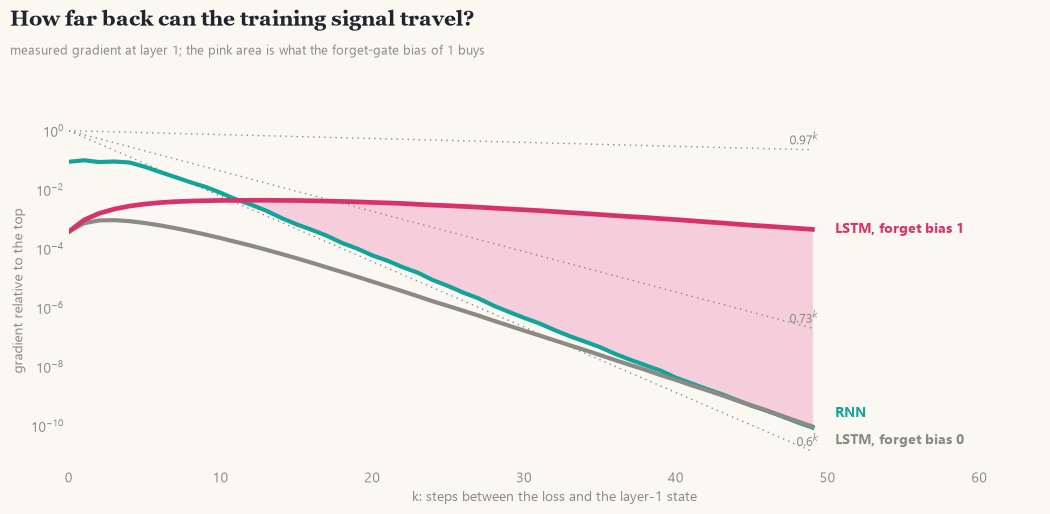

In [17]:
n_steps = g_rnn.shape[1]; k = np.arange(n_steps)[::-1]                      # distance (in steps) from the loss
fig, ax = plt.subplots(figsize=(10.5, 5.2))
for fval in (0.6, 0.73, 0.97):
    ax.semilogy(np.arange(n_steps), fval ** np.arange(n_steps), color=C["mute"], lw=1, ls=(0, (1, 3)))
    ax.text(n_steps - 0.6, fval ** (n_steps - 1) * 1.5, f"{fval}$^k$", fontsize=9, ha="right", color=C["mute"])
cur = {name: g[0] / g[-1, -1] for g, name in [(g_rnn, "RNN"), (g_lstm0, "LSTM, bias 0"), (g_lstm, "LSTM, bias 1")]}
ax.fill_between(k, cur["RNN"], cur["LSTM, bias 1"], where=cur["LSTM, bias 1"] > cur["RNN"], color=C["mag_l"], lw=0)
for name, col, lw in [("RNN", C["rnn"], 3), ("LSTM, bias 0", C["mute"], 3), ("LSTM, bias 1", C["lstm"], 3.4)]:
    ax.semilogy(k, cur[name], color=col, lw=lw, zorder=3)
ax.text(n_steps + 0.5, cur["LSTM, bias 1"][0], "LSTM, forget bias 1", color=C["lstm"], va="center", fontweight="bold")
ax.text(n_steps + 0.5, cur["RNN"][0] * 3.0, "RNN", color=C["rnn"], va="center", fontweight="bold"); ax.text(n_steps + 0.5, cur["LSTM, bias 0"][0] / 3.0, "LSTM, forget bias 0", color=C["mute"], va="center", fontweight="bold")
ax.set_xlim(0, n_steps + 14); ax.set_xlabel("k: steps between the loss and the layer-1 state"); ax.set_ylabel("gradient relative to the top")
headline(fig, "How far back can the training signal travel?", "measured gradient at layer 1; the pink area is what the forget-gate bias of 1 buys")
finish(fig, "C_grad_decay")

**Reading the decay curves.** The RNN and the LSTM with bias 0 follow the dotted line for a factor of about 0.6 per step down to $10^{-10}$ after 50 steps, nearly on top of each other. The LSTM with bias 1 starts lower (at small $k$ the signal still has to cross four layers) but then runs much flatter: between $k=12$ and $k=49$ it loses only about one order of magnitude, a factor of about 0.94 per step, which is steeper than the dotted line of 0.97 but far better than 0.6. The pink area marks what the bias buys: at 49 steps the difference is between six and seven orders of magnitude of gradient. This is the mechanism that the dataset notebooks rely on: the LSTM can learn from information that is many steps back, *provided* its forget gates start open (and, during training, learn to stay open where it matters).

## 7. Summary

| | 5-layer RNN | 5-layer LSTM |
|---|---|---|
| elementary functions | matmul, add, tanh | matmul, add, tanh, sigmoid, ⊙ |
| state per layer | $h_t$ | $h_t$ and cell $c_t$ |
| one step | $h_t=\tanh(x_tW_x+h_{t-1}W_h+b)$ | 3 gates + candidate, $c_t=f\odot c_{t-1}+i\odot g$, $h_t=o\odot\tanh c_t$ |
| parameters per layer | $FH+H^2+H$ | $4(FH+H^2+H)$ |
| gradient back one step | $\times W_h^\top\mathrm{diag}(1-h^2)$: shrinks | through $c$: $\times f_t$, kept when $f_t\approx1$ |
| PyTorch / Keras | `nn.RNN(num_layers=5)` / 5 × `SimpleRNN` | `nn.LSTM(num_layers=5)` / 5 × `LSTM` |

The hand-written versions matched PyTorch and Keras to float32 precision, so the frameworks compute exactly the compositions written above, and the experiments of §4 and §6 showed why the LSTM was invented: the plain RNN loses the gradient of early steps (a factor of about 0.6 per step), while the LSTM with forget bias 1 loses about 0.94 per step.

**Which one to choose, and why?** The LSTM's advantage is the cell path, which only pays off when the answer depends on information far back in the sequence. For short sequences, or when the last few steps carry most of the signal, a plain RNN can do nearly as well at a quarter of the cost of the recurrent parameters. The two dataset notebooks test exactly this. In the reviews (up to 100 words, with negative reviews often explaining at length) the LSTM is ahead of the RNN, and the gap grows with review length. In the stock volatility task the useful memory is only a few weeks, mostly the most recent days, and the LSTM is only marginally better than the RNN. Both results are what the mechanism of this notebook predicts.